# 01 · Eingangsprüfung und vertiefte EDA

**Ziel:** Übernommene Daten prüfen, Hypothesen zu Treibern der Fluktuation untersuchen.  
**Input:** `data/input/ (bereinigte Daten)`  
**Output:** `Grafiken in reports/figures/, Hypothesen für die Modellierung`

## 1. Daten laden

In [1]:
# Standard setup — run first
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sonnenfeld import config, plotting

plotting.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:

# Load the Gold table received from the cleaning phase
df = pd.read_csv(config.INPUT_FILE)

## 2. Eingangsprüfung: Zeilen, Datentypen, fehlende Werte, Duplikate, Wertebereiche
*Warum:* Daten wurden von Dritten bereinigt → vor der Analyse prüfen

### 2.1 Struktur und Datentypen

In [3]:
# cheack that the data loaaded correctly
df.head()

,mitarbeiter_id,alter,geschlecht,abteilung,position,eintrittsdatum,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,gehalt_status,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt
0,MA-00000,42,weiblich,Produktion,Junior,2024-03-03,1,22,"48,071.00","48,071.00",Original,3,5.00,3,0
1,MA-00001,36,weiblich,IT,Senior,2025-05-07,0,8,"53,178.00","53,178.00",Original,0,4.00,8,0
2,MA-00002,44,männlich,Produktion,Junior,2025-12-20,0,0,"34,614.00","34,614.00",Original,10,2.00,5,0
3,MA-00003,53,weiblich,IT,Senior,2025-10-12,0,3,"59,594.00","59,594.00",Original,0,5.00,8,0
4,MA-00004,35,männlich,Vertrieb,Senior,2021-04-13,4,57,"70,287.00","70,287.00",Original,0,4.00,8,0


In [4]:
# Basic structure
print("Shape:", df.shape)
print("Unique IDs:", df[config.ID_COL].nunique())
print("Duplicate rows:", df.duplicated().sum())
print()
df.info()

Shape: (10000, 15)
Unique IDs: 10000
Duplicate rows: 0

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   mitarbeiter_id                 10000 non-null  str    
 1   alter                          10000 non-null  int64  
 2   geschlecht                     10000 non-null  str    
 3   abteilung                      10000 non-null  str    
 4   position                       10000 non-null  str    
 5   eintrittsdatum                 10000 non-null  str    
 6   betriebszugehoerigkeit_jahre   10000 non-null  int64  
 7   betriebszugehoerigkeit_monate  10000 non-null  int64  
 8   gehalt_brutto                  9800 non-null   float64
 9   gehalt_final                   10000 non-null  float64
 10  gehalt_status                  10000 non-null  str    
 11  ueberstunden_monat             10000 non-null  int64  
 12  zu

In [5]:
print("Rows:", df.shape[0])
print("Unique IDs:", df[config.ID_COL].nunique())

Rows: 10000
Unique IDs: 10000


**Erkenntnis:** 10.000 Zeilen, 10.000 IDs, keine Duplikate; Typen plausibel
       (zufriedenheit als float wegen NaN, eintrittsdatum als Text)

### 2.2 Wertebereiche und Kategorien 

In [6]:
#summary statistics
df.describe()

,alter,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt
count,"10,000.00","10,000.00","10,000.00","9,800.00","10,000.00","10,000.00","9,500.00","10,000.00","10,000.00"
mean,37.62,4.21,56.59,"57,907.49","57,582.77",4.53,3.13,8.03,0.17
std,9.63,4.40,53.02,"27,719.17","21,765.13",4.94,1.12,2.83,0.37
min,20.00,0.00,0.00,"-5,000.00","25,000.00",0.00,1.00,0.00,0.00
25%,31.00,1.00,18.00,"41,852.50","41,897.50",1.00,2.00,6.00,0.00
50%,37.00,3.00,40.00,"51,514.50","51,472.50",3.00,3.00,8.00,0.00
75%,44.00,6.00,80.00,"68,467.50","68,426.50",7.00,4.00,10.00,0.00
max,64.00,35.00,421.00,"1,200,000.00","184,060.00",40.00,5.00,23.00,1.00


In [7]:
#Checking unique values in categorical columns
df['position'].value_counts()

position
Junior     4991
Senior     3010
Lead       1514
Manager     485
Name: count, dtype: int64

In [8]:
df['abteilung'].value_counts()

abteilung
Produktion    2080
IT            2036
Vertrieb      2021
Marketing     1459
Finanzen       962
Logistik       934
Personal       508
Name: count, dtype: int64

In [9]:
df['geschlecht'].value_counts()

geschlecht
männlich    5201
weiblich    4500
divers       299
Name: count, dtype: int64

In [10]:
# Plausibility check: age at entry = current age − tenure in years
eintrittsalter = df["alter"] - df["betriebszugehoerigkeit_monate"] / 12

print(eintrittsalter.describe().round(1))
print("Entry age below 16:", (eintrittsalter < 16).sum())

count   10,000.00
mean        32.90
std         10.10
min         17.00
25%         25.00
50%         32.70
75%         39.90
max         63.80
dtype: float64
Entry age below 16: 0


In [11]:
df[['gehalt_brutto', 'gehalt_final']].describe()

,gehalt_brutto,gehalt_final
count,"9,800.00","10,000.00"
mean,"57,907.49","57,582.77"
std,"27,719.17","21,765.13"
min,"-5,000.00","25,000.00"
25%,"41,852.50","41,897.50"
50%,"51,514.50","51,472.50"
75%,"68,467.50","68,426.50"
max,"1,200,000.00","184,060.00"


**Erkenntnis:** Alle Wertebereiche sind plausibel. Das minimale Eintrittsalter
(alter − Betriebszugehörigkeit in Monaten / 12) liegt bei 17 Jahren, was einem
Ausbildungsbeginn entspricht (Genauigkeit ±1 Jahr, da `alter` in vollen Jahren angegeben ist).
`gehalt_brutto` enthält mindestens einen negativen Wert (−5.000 €); die Bereinigung
wird in Abschnitt 2.3 geprüft.

Hinweis: Einige Gehälter liegen unter dem Jahresäquivalent des gesetzlichen Mindestlohns
bei Vollzeit (ca. 26.700 € bei 12,82 €/h, 2025). Sie sind plausibel (z. B. Teilzeit,
Werkstudierende), aber ohne Angabe zum Arbeitszeitmodell nicht eindeutig interpretierbar
(siehe Limitation 4).

### 2.3 Von Jakub erstellte Spalten 

#### Gehalt

In [12]:
df['gehalt_status'].value_counts()

gehalt_status
Original             9795
Fehlend imputiert     200
Ausreißer ersetzt       5
Name: count, dtype: int64

In [13]:
#checking the outliers that were replaced in the salary column
df[(df['gehalt_status'] == 'Ausreißer ersetzt')]

,mitarbeiter_id,alter,geschlecht,abteilung,position,eintrittsdatum,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,gehalt_status,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt
398,MA-00398,36,männlich,Produktion,Senior,2021-07-18,4,53,"750,000.00","62,254.50",Ausreißer ersetzt,0,1.00,4,0
4250,MA-04250,48,männlich,Produktion,Junior,2010-10-22,15,182,"1,200,000.00","41,601.00",Ausreißer ersetzt,0,4.00,15,0
6064,MA-06064,39,weiblich,Produktion,Manager,2021-02-22,4,58,"-5,000.00","113,890.00",Ausreißer ersetzt,1,2.00,11,0
6554,MA-06554,35,männlich,IT,Senior,2019-03-18,6,81,"500,000.00","62,299.00",Ausreißer ersetzt,1,5.00,7,0
9716,MA-09716,40,männlich,Vertrieb,Junior,2024-09-07,1,16,"999,999.00","42,157.00",Ausreißer ersetzt,0,3.00,9,1


In [14]:
df[df['gehalt_brutto'] < 0]

,mitarbeiter_id,alter,geschlecht,abteilung,position,eintrittsdatum,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,gehalt_status,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt
6064,MA-06064,39,weiblich,Produktion,Manager,2021-02-22,4,58,"-5,000.00","113,890.00",Ausreißer ersetzt,1,2.00,11,0


In [15]:
df.sort_values(by='gehalt_brutto', ascending=False).head(10)

,mitarbeiter_id,alter,geschlecht,abteilung,position,eintrittsdatum,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,gehalt_status,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt
4250,MA-04250,48,männlich,Produktion,Junior,2010-10-22,15,182,"1,200,000.00","41,601.00",Ausreißer ersetzt,0,4.00,15,0
9716,MA-09716,40,männlich,Vertrieb,Junior,2024-09-07,1,16,"999,999.00","42,157.00",Ausreißer ersetzt,0,3.00,9,1
398,MA-00398,36,männlich,Produktion,Senior,2021-07-18,4,53,"750,000.00","62,254.50",Ausreißer ersetzt,0,1.00,4,0
6554,MA-06554,35,männlich,IT,Senior,2019-03-18,6,81,"500,000.00","62,299.00",Ausreißer ersetzt,1,5.00,7,0
1183,MA-01183,22,männlich,Produktion,Manager,2021-02-20,4,58,"184,060.00","184,060.00",Original,4,4.00,9,0
7526,MA-07526,48,weiblich,Produktion,Manager,2023-08-24,2,28,"181,216.00","181,216.00",Original,4,5.00,10,0
3209,MA-03209,42,männlich,IT,Manager,2025-05-07,0,8,"177,633.00","177,633.00",Original,0,2.00,9,0
6428,MA-06428,51,männlich,Finanzen,Manager,2020-12-11,5,61,"174,630.00","174,630.00",Original,11,4.00,13,0
9595,MA-09595,33,männlich,Vertrieb,Manager,2025-10-12,0,3,"174,049.00","174,049.00",Original,0,5.00,3,0
2834,MA-02834,35,weiblich,IT,Manager,2023-12-17,2,24,"170,798.00","170,798.00",Original,0,4.00,7,0


In [16]:
df.sort_values(by='gehalt_brutto', ascending=True).head(10)

,mitarbeiter_id,alter,geschlecht,abteilung,position,eintrittsdatum,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,gehalt_status,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt
6064,MA-06064,39,weiblich,Produktion,Manager,2021-02-22,4,58,"-5,000.00","113,890.00",Ausreißer ersetzt,1,2.00,11,0
4086,MA-04086,46,männlich,Produktion,Junior,2020-09-01,5,64,"25,000.00","25,000.00",Original,2,2.00,6,0
3530,MA-03530,52,männlich,Vertrieb,Junior,2021-12-02,4,49,"25,000.00","25,000.00",Original,4,4.00,10,1
2143,MA-02143,40,weiblich,Marketing,Junior,2022-08-04,3,41,"25,000.00","25,000.00",Original,12,2.00,10,1
4795,MA-04795,25,männlich,Personal,Junior,2025-09-18,0,3,"25,000.00","25,000.00",Original,4,1.00,7,0
8000,MA-08000,37,männlich,Produktion,Junior,2021-04-02,4,57,"25,000.00","25,000.00",Original,5,4.00,7,0
7316,MA-07316,28,divers,Produktion,Junior,2023-02-26,2,34,"25,000.00","25,000.00",Original,9,3.00,8,0
4956,MA-04956,36,männlich,Vertrieb,Junior,2022-07-27,3,41,"25,000.00","25,000.00",Original,1,NaN,10,0
1947,MA-01947,37,männlich,Finanzen,Junior,2015-08-02,10,125,"25,000.00","25,000.00",Original,2,4.00,7,0
1263,MA-01263,28,weiblich,Vertrieb,Junior,2015-04-17,10,128,"25,000.00","25,000.00",Original,1,4.00,7,0


In [17]:
# Rows where final salary differs from original (NaN != value counts as different)
changed = df["gehalt_brutto"] != df["gehalt_final"]
print(df.loc[changed, "gehalt_status"].value_counts())

# Cross-checks: imputed rows had no original value; final salary has no gaps
imputed = df["gehalt_status"] == "Fehlend imputiert"
print("Imputed rows with an original value:", df.loc[imputed, "gehalt_brutto"].notna().sum())
print("Missing values in gehalt_final:", df["gehalt_final"].isna().sum())

gehalt_status
Fehlend imputiert    200
Ausreißer ersetzt      5
Name: count, dtype: int64
Imputed rows with an original value: 0
Missing values in gehalt_final: 0


**Erkenntnis:** Alle Abweichungen zwischen `gehalt_brutto` und `gehalt_final` sind in
`gehalt_status` dokumentiert: 5 ersetzte Ausreißer (u. a. −5.000 € und 999.999 €) und
200 imputierte fehlende Werte. Keine undokumentierten Änderungen.
Hinweis an die Bereinigung: Im Cleaning-Log sind 4 statt 5 Ausreißer angegeben;
die Regel zur Ausreißererkennung ist zu dokumentieren.

Die Ausreißerregel ist nachvollziehbar: negative Werte sowie eine deutliche Lücke
oberhalb von 184.060 € (nächster Wert: 500.000 €).

#### Betriebszugehörigkeit

In [18]:
# --- Part 1: months and years consistent? ---
years_from_months = df["betriebszugehoerigkeit_monate"] // 12
mismatch = years_from_months != df["betriebszugehoerigkeit_jahre"]
print("Rows where months // 12 != years:", mismatch.sum())


# --- Part 2: reconstruct the reference date used for tenure ---
# Convert entry date; unparseable values become NaT so we can count them
eintritt = pd.to_datetime(df["eintrittsdatum"], errors="coerce")
print("Unparseable entry dates:", eintritt.isna().sum())

# Exact month arithmetic: entry month + tenure in months = reference month
month_index = (
    eintritt.dt.year * 12
    + (eintritt.dt.month - 1)
    + df["betriebszugehoerigkeit_monate"]
)
reference_month = (
    (month_index // 12).astype("Int64").astype(str)
    + "-"
    + (month_index % 12 + 1).astype("Int64").astype(str).str.zfill(2)
)

reference_month.value_counts().head(10)

Rows where months // 12 != years: 390
Unparseable entry dates: 0


2026-01    5050
2025-12    4950
Name: count, dtype: int64

**Erkenntnis:** Die Betriebszugehörigkeit in Monaten ist auf den 31.12.2025 berechnet
(rekonstruiertes Referenzdatum: 12/2025 bzw. 01/2026 durch Rundung) und enthält keine
Informationen nach dem Stichtag. Laut Dokumentation sind die Monate gerundet; dadurch
weichen 390 Zeilen um ein Jahr von `betriebszugehoerigkeit_jahre` (vollendete Jahre) ab.

**Entscheidung:** Beide Spalten werden je nach Zweck verwendet:
`betriebszugehoerigkeit_jahre` (vollendete Jahre) für die Gruppenbildung in F2, damit
die Gruppengrenzen exakt sind; `betriebszugehoerigkeit_monate` (gerundet) für das Modell,
da die höhere Auflösung dort mehr Information liefert.

### 2.4 Fehlende Werte in `zufriedenheit`

Prüffrage 1: Hängt das Fehlen mit Kündigungen zusammen?

In [19]:
#is the target variable correlated with missing values in the satisfaction column?
#create a new column that indicates whether the satisfaction value is missing
df['zufriedenheit_fehlt'] = df['zufriedenheit'].isna()
#calculate the terminatio rate using the mean of the target variable for each group
df.groupby('zufriedenheit_fehlt')[config.TARGET].agg(['count', 'sum', 'mean'])

,count,sum,mean
zufriedenheit_fehlt,,,
False,9500,1605,0.17
True,500,87,0.17


**Erkenntnis 1:** Hypothese nicht bestätigt. Die Fluktuationsquote der Personen ohne
Zufriedenheitswert (17,4 %, n = 500) unterscheidet sich nicht nennenswert von der
der übrigen (16,9 %, n = 9.500).

Prüffrage 2: Konzentrieren sich fehlende Werte in Abteilungen oder Hierarchieebenen?

In [20]:
df.groupby('abteilung')['zufriedenheit_fehlt']. agg(['count', 'mean']).sort_values(by='mean', ascending=False)

,count,mean
abteilung,,
Finanzen,962,0.06
Logistik,934,0.06
IT,2036,0.05
Produktion,2080,0.05
Vertrieb,2021,0.05
Marketing,1459,0.05
Personal,508,0.04


In [21]:
df.groupby('position')['zufriedenheit_fehlt'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)

,count,mean
position,,
Senior,3010,0.05
Junior,4991,0.05
Manager,485,0.05
Lead,1514,0.05


In [22]:
df.groupby(['abteilung', 'position'])['zufriedenheit_fehlt'].agg(['count', 'mean']).sort_values(by=['abteilung', 'mean'])

count  mean
abteilung  position             
Finanzen   Manager      42  0.00
           Junior      467  0.04
           Lead        158  0.08
           Senior      295  0.08
IT         Lead        319  0.04
           Senior      612  0.05
           Junior      991  0.06
           Manager     114  0.06
Logistik   Lead        141  0.04
           Junior      448  0.05
           Senior      296  0.07
           Manager      49  0.08
Marketing  Senior      426  0.03
           Junior      760  0.05
           Lead        210  0.06
           Manager      63  0.06
Personal   Lead         74  0.01
           Junior      261  0.04
           Manager      22  0.05
           Senior      151  0.05
Produktion Manager     103  0.04
           Senior      632  0.05
           Junior     1043  0.05
           Lead        302  0.06
Vertrieb   Lead        310  0.03
           Manager      92  0.04
           Senior      598  0.05
           Junior     1021  0.05

In [23]:
from scipy.stats import chi2_contingency

def chi2_missing_test(df, group_cols):
    """Chi-square test: is missing satisfaction independent of the given group(s)?"""
    # Contingency table: counts of missing (True) / not missing (False) per group
    table = pd.crosstab(
        [df[col] for col in group_cols],
        df["zufriedenheit_fehlt"],
    )
    chi2, p, dof, expected = chi2_contingency(table)
    print(f"Groups: {' × '.join(group_cols)} | chi² = {chi2:.2f}, df = {dof}, p = {p:.3f}")
    return table

# Test 1: by department
chi2_missing_test(df, ["abteilung"])

# Test 2: by position
chi2_missing_test(df, ["position"])

# Test 3: department × position
chi2_missing_test(df, ["abteilung", "position"])

Groups: abteilung | chi² = 4.04, df = 6, p = 0.671
Groups: position | chi² = 0.85, df = 3, p = 0.838
Groups: abteilung × position | chi² = 26.69, df = 27, p = 0.481


zufriedenheit_fehlt  False  True 
abteilung  position              
Finanzen   Junior      447     20
           Lead        146     12
           Manager      42      0
           Senior      272     23
IT         Junior      936     55
           Lead        306     13
           Manager     107      7
           Senior      580     32
Logistik   Junior      426     22
           Lead        136      5
           Manager      45      4
           Senior      275     21
Marketing  Junior      722     38
           Lead        198     12
           Manager      59      4
           Senior      414     12
Personal   Junior      250     11
           Lead         73      1
           Manager      21      1
           Senior      144      7
Produktion Junior      991     52
           Lead        285     17
           Manager      99      4
           Senior      602     30
Vertrieb   Junior      968     53
           Lead        301      9
           Manager      88      4
           Senior      567     31

**Erkenntnis:** Die fehlenden Zufriedenheitswerte (n = 500, 5,0 %) sind unabhängig von
Abteilung (χ² = 4,04, df = 6, p = 0,671), Hierarchieebene (χ² = 0,85, df = 3, p = 0,838)
und deren Kombination (χ² = 26,69, df = 27, p = 0,481). Die Voraussetzung des Tests
(erwartete Häufigkeiten) ist erfüllt. Es gibt keine Konzentration in bestimmten Gruppen.

Prüffrage 3: Unterscheiden sich Personen ohne Wert in numerischen Merkmalen?

In [24]:
from scipy.stats import mannwhitneyu

# Numeric columns to compare between respondents and non-respondents
numeric_cols = [
    "betriebszugehoerigkeit_monate",
    "alter",
    "gehalt_final",
    "ueberstunden_monat",
    "abwesenheitstage_jahr",
]

missing = df["zufriedenheit_fehlt"]
results = []

for col in numeric_cols:
    with_value = df.loc[~missing, col].dropna()
    without_value = df.loc[missing, col].dropna()
    stat, p = mannwhitneyu(with_value, without_value)
    results.append({
        "merkmal": col,
        "median_mit_wert": with_value.median(),
        "median_ohne_wert": without_value.median(),
        "p_wert": round(p, 3),
    })

pd.DataFrame(results)

,merkmal,median_mit_wert,median_ohne_wert,p_wert
0,betriebszugehoerigkeit_monate,40.00,40.50,0.96
1,alter,37.00,38.00,0.39
2,gehalt_final,"51,450.50","51,658.50",0.94
3,ueberstunden_monat,3.00,3.00,0.40
4,abwesenheitstage_jahr,8.00,8.00,0.29


**Erkenntnis:** ie Ergebnisse sprechen für zufällig fehlende Werte (MCAR): Es gibt keinen Zusammenhang
mit anderen Merkmalen und keine erhöhte Fluktuation bei fehlenden Werten.

**Entscheidung:** Zeilen ohne Zufriedenheitswert werden nur in Analysen ausgeschlossen,
die `zufriedenheit` verwenden (inkl. Modell). Bei MCAR verzerrt dies die Ergebnisse nicht.

## 3. Gesamtfluktuationsrate

In [25]:
fluktuation = df['gekuendigt'].value_counts() / df.shape[0] * 100

print(f"Fluktuation: {round(fluktuation[1],1)}%")
print(df['gekuendigt'].value_counts())

Fluktuation: 16.9%
gekuendigt
0    8308
1    1692
Name: count, dtype: int64


In [26]:
# Overall attrition rate (reference value for all group comparisons)
n_mitarbeitende = len(df)
n_kuendigungen = df[config.TARGET].sum()
gesamtquote = n_kuendigungen / n_mitarbeitende

# 95 % confidence interval for a proportion (normal approximation)
fehlermarge = 1.96 * np.sqrt(gesamtquote * (1 - gesamtquote) / n_mitarbeitende)
untergrenze = gesamtquote - fehlermarge
obergrenze = gesamtquote + fehlermarge

print(f"Mitarbeitende:      {n_mitarbeitende:,}")
print(f"Kündigungen:        {n_kuendigungen:,}")
print(f"Fluktuationsquote:  {gesamtquote:.1%}")
print(f"95-%-Intervall:     {untergrenze:.1%} – {obergrenze:.1%}")


Mitarbeitende:      10,000
Kündigungen:        1,692
Fluktuationsquote:  16.9%
95-%-Intervall:     16.2% – 17.7%


**Erkenntnis:** Die Fluktuationsquote beträgt 16,9 % (1.692 von 10.000 Mitarbeitenden;
95-%-Konfidenzintervall: 16,2 % – 17,7 %). Damit bestätigen die Daten die Schätzung der
Personalabteilung von rund 17 %. Der Anstieg gegenüber früher (unter 10 %) ist mit diesem
Datensatz nicht überprüfbar (siehe Limitation 1).

Diese Quote dient als Referenzwert für alle Gruppenvergleiche. Für das Modell bedeutet sie:
Ein Baseline-Modell, das immer „keine Kündigung" vorhersagt, erreicht bereits eine
Accuracy von 83,1 %.

## 4. Univariate Verteilungen

In [27]:
df['ueberstunden_monat'].describe()

count   10,000.00
mean         4.53
std          4.94
min          0.00
25%          1.00
50%          3.00
75%          7.00
max         40.00
Name: ueberstunden_monat, dtype: float64

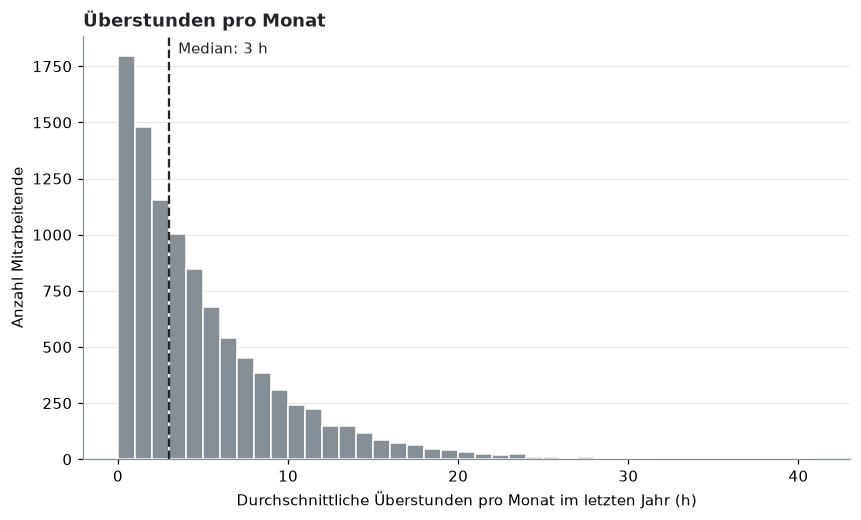

In [28]:
# Distribution of monthly overtime (univariate)
col = "ueberstunden_monat"
median = df[col].median()

fig, ax = plt.subplots()

# One bin per hour; integer-aligned edges so each bar = exactly one value
ax.hist(
    df[col],
    bins=range(0, int(df[col].max()) + 2),
    color=plotting.COLORS["neutral"],
    edgecolor="white",
    linewidth=1,
)

# Median as reference line, labelled directly instead of a legend
ax.axvline(median, color=plotting.COLORS["dark"], linewidth=1.5, linestyle="--")
ax.annotate(
    f"Median: {median:.0f} h",
    xy=(median, 1), xycoords=("data", "axes fraction"),
    xytext=(6, -4), textcoords="offset points",
    ha="left", va="top", color=plotting.COLORS["dark"],
)

ax.set_title("Überstunden pro Monat")
ax.set_xlabel("Durchschnittliche Überstunden pro Monat im letzten Jahr (h)")
ax.set_ylabel("Anzahl Mitarbeitende")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plotting.save(fig, "04_ueberstunden_verteilung")
plt.show()

In [29]:
# Share of employees without any overtime
ohne_ueberstunden = df["ueberstunden_monat"] == 0
anteil_ohne_ueberstunden = ohne_ueberstunden.mean()
print(f"Anteil ohne Überstunden: {anteil_ohne_ueberstunden:.1%}")

# Percentiles to derive group boundaries
df["ueberstunden_monat"].quantile([0.25, 0.5, 0.75, 0.9])

Anteil ohne Überstunden: 18.0%


0.25    1.00
0.50    3.00
0.75    7.00
0.90   11.00
Name: ueberstunden_monat, dtype: float64

In [30]:
# Overtime groups: boundaries follow percentiles (P50 = 3, P75 = 7, P90 = 11);
# 0 h is its own group because of zero inflation (18 %)
ueberstunden_bins = [-1, 0, 3, 7, 11, np.inf]
ueberstunden_labels = [
    "Keine (0 h)",
    "Niedrig (1–3 h)",
    "Mittel (4–7 h)",
    "Hoch (8–11 h)",
    "Sehr hoch (≥ 12 h)",
]

df["ueberstunden_gruppe"] = pd.cut(
    df["ueberstunden_monat"],
    bins=ueberstunden_bins,
    labels=ueberstunden_labels,
)

# Size of each group (count and share)
pd.DataFrame({
    "anzahl": df["ueberstunden_gruppe"].value_counts(sort=False),
    "anteil": df["ueberstunden_gruppe"].value_counts(sort=False, normalize=True).round(3),
})

,anzahl,anteil
ueberstunden_gruppe,,
Keine (0 h),1796,0.18
Niedrig (1–3 h),3634,0.36
Mittel (4–7 h),2521,0.25
Hoch (8–11 h),1159,0.12
Sehr hoch (≥ 12 h),890,0.09


**Erkenntnis:** Die Überstunden sind stark rechtsschief verteilt (Median 3 h, P90 = 11 h,
Max. 40 h). 18 % der Mitarbeitenden leisten keine Überstunden (Null-Inflation); mögliche
Gründe sind Freizeitausgleich, pauschal abgegoltene Überstunden oder Teilzeit.
Auch die oberen 10 % leisten im Schnitt weniger als 3 Überstunden pro Woche.

**Gruppenbildung:** Grenzen anhand der Perzentile (P50 = 3 h, P75 = 7 h, P90 = 11 h),
0 h als eigene Gruppe. Kleinste Gruppe: „Sehr hoch" mit 890 Personen (9 %).

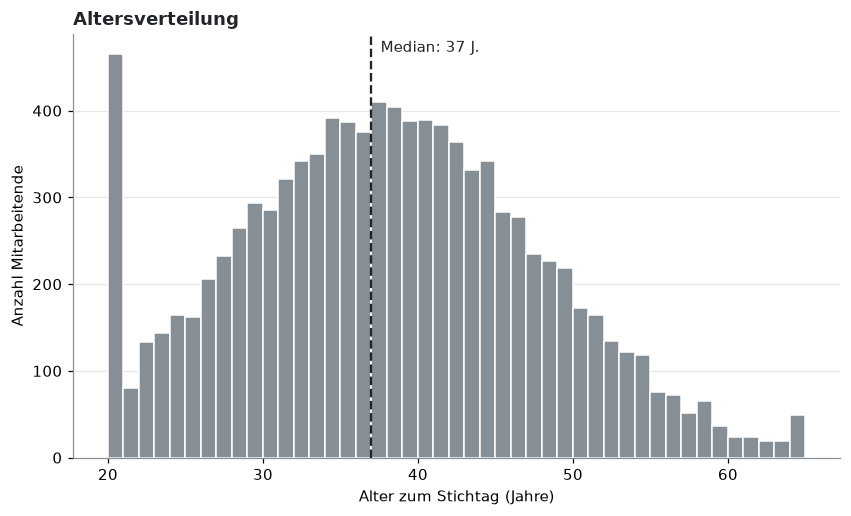

In [31]:
fig, ax = plotting.histogram(
    df, "alter",
    title="Altersverteilung",
    xlabel="Alter zum Stichtag (Jahre)",
    unit="J.",
    save_as="04_alter_verteilung",
)
plt.show()

**Erkenntnis:** Das Alter ist annähernd glockenförmig verteilt (Median 37 Jahre,
Spannweite 20–64). Auffällig ist eine starke Häufung genau beim Minimum von 20 Jahren
und eine schwache beim Maximum von 64 Jahren. Das Muster spricht für eine Kappung der
Werte bei der Datengenerierung (Werte < 20 auf 20 gesetzt, > 64 auf 64). Die Häufung
ist am unteren Rand größer, weil dieser näher am Median liegt.
**Konsequenz:** „20 Jahre" bedeutet faktisch „20 Jahre oder jünger". Für die
Altersgruppen ist das unproblematisch, da diese Werte ohnehin in die jüngste Gruppe fallen.

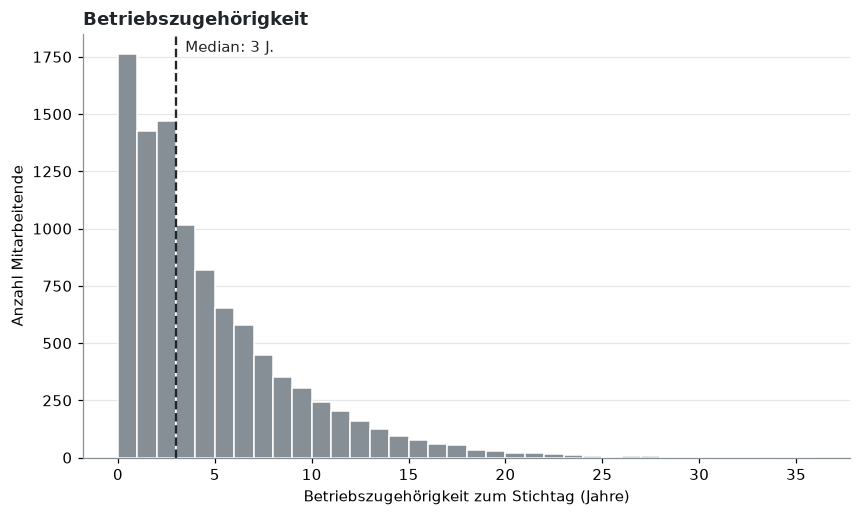

In [32]:
fig, ax = plotting.histogram(
    df, "betriebszugehoerigkeit_jahre",
    title="Betriebszugehörigkeit",
    xlabel="Betriebszugehörigkeit zum Stichtag (Jahre)",
    unit="J.",
    save_as="04_betriebszugehoerigkeit_verteilung",
)
plt.show()

 **Erkenntnis:** Die Betriebszugehörigkeit ist rechtsschief verteilt (Median 3 Jahre).
Die größte Gruppe sind Mitarbeitende mit weniger als einem Jahr (1.761; 17,6 %), was
bei einer Fluktuationsquote von 16,9 % dem jährlichen Ersatzbedarf entspricht.
Ab 3 Jahren nimmt jede Gruppe um rund 20 % ab. Auffällig: Die Gruppen mit 1 und 2 Jahren
sind nahezu gleich groß, danach folgt ein Rückgang um 31 %. Das ist mit verstärkten
Einstellungen in den letzten drei Jahren vereinbar, z. B. als Ersatz für die gestiegene
Fluktuation. Mit einer Stichtagsbetrachtung lässt sich das jedoch nicht belegen
(Einstellungs- und Verbleibseffekte sind nicht trennbar; siehe Limitation 1).

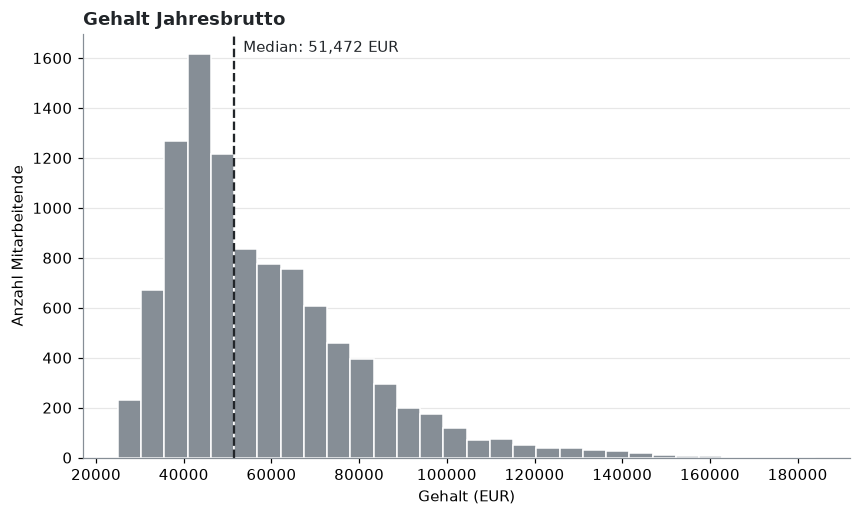

In [33]:
fig, ax = plotting.histogram(
    df, "gehalt_final",
    title="Gehalt Jahresbrutto",
    xlabel="Gehalt (EUR)",
    unit="EUR",
    save_as="04_gehalt_verteilung",
)
plt.show()

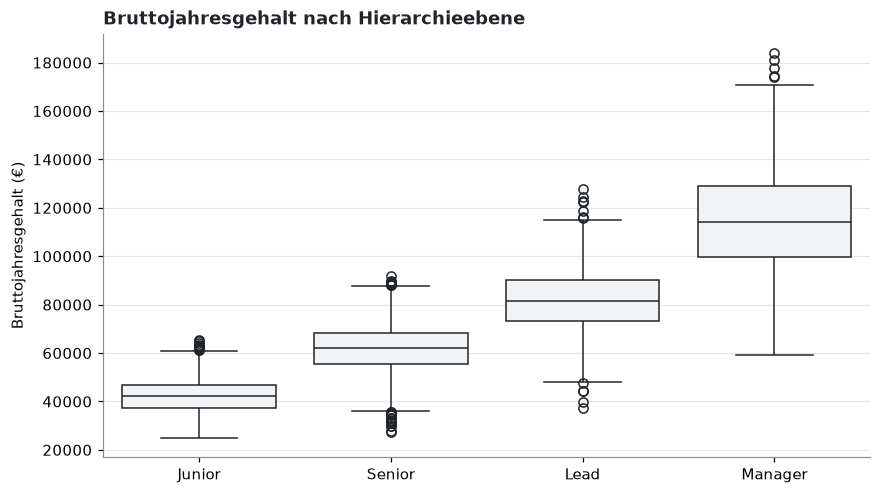

In [34]:
order = ["Junior", "Senior", "Lead", "Manager"]

fig, ax = plt.subplots()
sns.boxplot(
    data=df, x="position", y="gehalt_final", order=order,
    color=plotting.COLORS["light"], linecolor=plotting.COLORS["dark"], linewidth=1,
    ax=ax,
)
ax.set_title("Bruttojahresgehalt nach Hierarchieebene")
ax.set_xlabel("")
ax.set_ylabel("Bruttojahresgehalt (€)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plotting.save(fig, "04_gehalt_nach_position")
plt.show()

**Erkenntnis:** Das Bruttojahresgehalt ist rechtsschief verteilt (Häufung bei 40–45 T€,
wenige Werte über 100 T€); am Minimum von 25.000 € gibt es keine Häufung, also keine
Kappung. Die Verteilung ist eine Mischung der vier Hierarchieebenen: Die mittleren 50 %
der Gehälter überschneiden sich zwischen den Ebenen nicht; der kleinste Abstand liegt
zwischen Senior und Lead.
**Konsequenz:** Absolutes Gehalt und Hierarchieebene sind stark voneinander abhängig.
Für F3 und das Modell wird daher das relative Gehalt innerhalb der Vergleichsgruppe
(Abteilung × Hierarchieebene) verwendet.

In [35]:
df["zufriedenheit"].value_counts().sort_index()

zufriedenheit
1.00    1006
2.00    1492
3.00    3218
4.00    2857
5.00     927
Name: count, dtype: int64

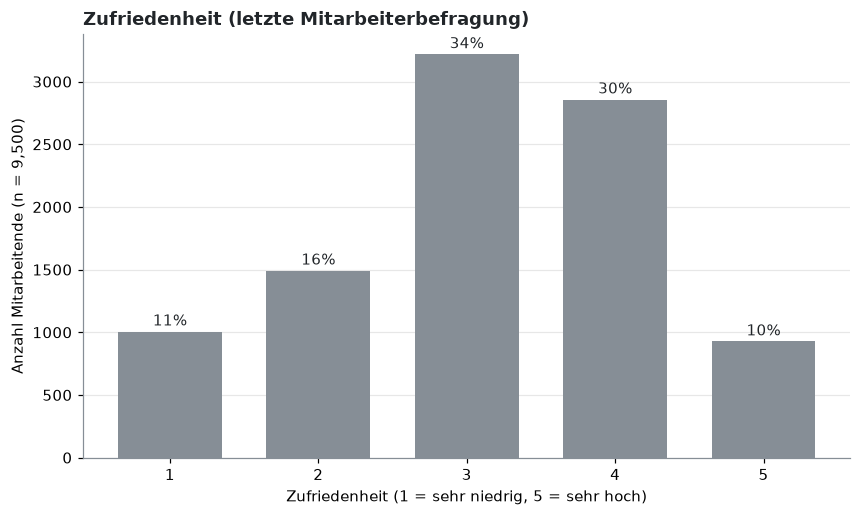

In [36]:
# Satisfaction is ordinal (1–5): bar chart of counts per value, not a histogram
counts = df["zufriedenheit"].value_counts().sort_index()
n_valid = counts.sum()

fig, ax = plt.subplots()
ax.bar(
    counts.index.astype(int).astype(str), counts.values,
    color=plotting.COLORS["neutral"], width=0.7,
)

# Share above each bar
for x, value in zip(counts.index.astype(int).astype(str), counts.values):
    ax.annotate(f"{value / n_valid:.0%}", (x, value),
                xytext=(0, 4), textcoords="offset points",
                ha="center", color=plotting.COLORS["dark"])

ax.set_title("Zufriedenheit (letzte Mitarbeiterbefragung)")
ax.set_xlabel("Zufriedenheit (1 = sehr niedrig, 5 = sehr hoch)")
ax.set_ylabel(f"Anzahl Mitarbeitende (n = {n_valid:,})")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plotting.save(fig, "04_zufriedenheit_verteilung")
plt.show()

**Erkenntnis:** Die Zufriedenheit (n = 9.500) konzentriert sich auf die Werte 3 (34 %)
und 4 (30 %). Die Mitte der Skala ist zur positiven Seite verschoben (4: 30 % vs. 2: 16 %),
die Extremwerte sind ausgeglichen (1: 11 %, 5: 10 %).
Top-2-Box (4–5): 40 %, Bottom-2-Box (1–2): 27 %. Mehr als jede vierte Person ist unzufrieden.
Da die Skala ordinal ist, wird der Median als Lagemaß verwendet.
(Summe der Anteile rundungsbedingt 101 %.)

In [37]:
df['abwesenheitstage_jahr'].describe()

count   10,000.00
mean         8.03
std          2.83
min          0.00
25%          6.00
50%          8.00
75%         10.00
max         23.00
Name: abwesenheitstage_jahr, dtype: float64

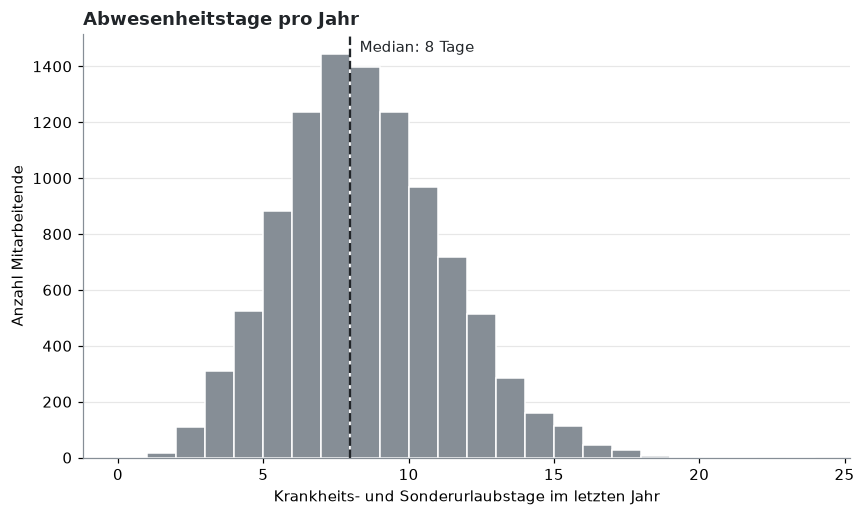

In [38]:
fig, ax = plotting.histogram(
    df, "abwesenheitstage_jahr",
    title="Abwesenheitstage pro Jahr",
    xlabel="Krankheits- und Sonderurlaubstage im letzten Jahr",
    unit="Tage",
    save_as="04_abwesenheitstage_verteilung",
)
plt.show()

**Erkenntnis:** Die Abwesenheitstage sind annähernd glockenförmig und leicht rechtsschief
verteilt (Median 8 Tage, P75 = 10 Tage, Spannweite 0–23), wie für Zähldaten typisch.
An den Rändern gibt es keine Häufungen, also keine Hinweise auf eine Kappung.

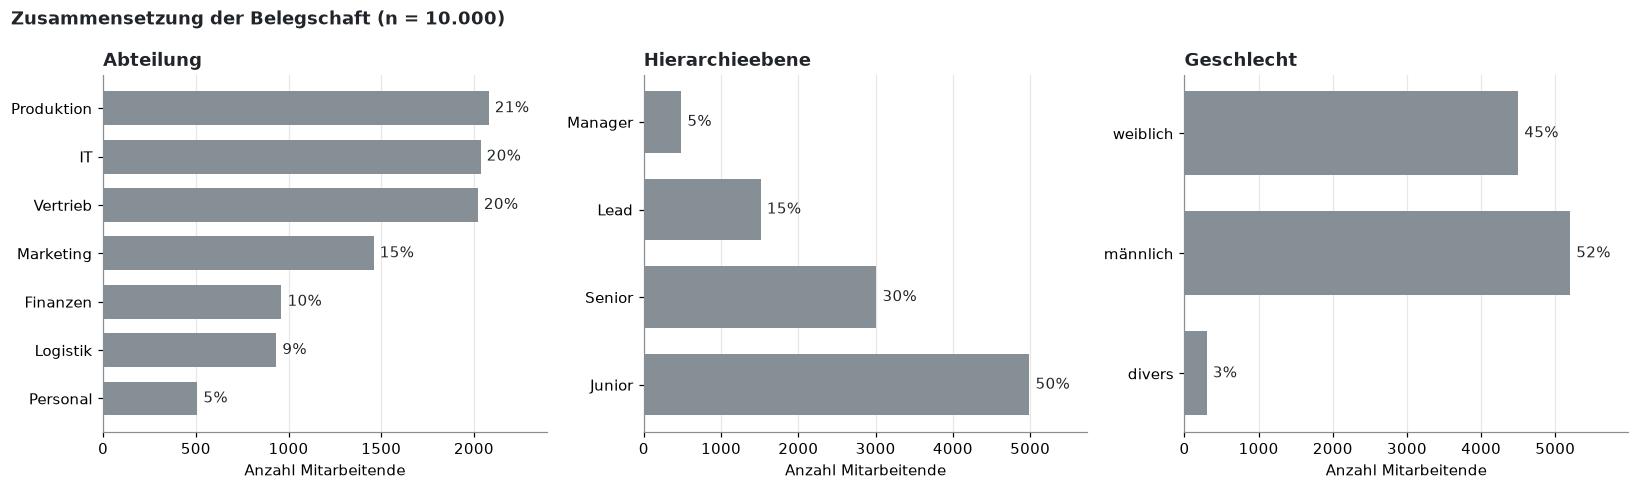

In [39]:
# Composition of the workforce: three categorical variables side by side
specs = [
    ("abteilung", "Abteilung", None),                                  # sorted by size
    ("position", "Hierarchieebene", ["Junior", "Senior", "Lead", "Manager"]),
    ("geschlecht", "Geschlecht", ["divers", "männlich", "weiblich"]),  # fixed order w/m/d, top to bottom
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (col, title, order) in zip(axes, specs):
    counts = df[col].value_counts()
    if order:
        counts = counts.reindex(order)          # fixed order, first item drawn at the bottom
    else:
        counts = counts.iloc[::-1]              # largest on top

    ax.barh(counts.index, counts.values, color=plotting.COLORS["neutral"], height=0.7)
    for y, value in zip(counts.index, counts.values):
        ax.annotate(f"{value / len(df):.0%}", (value, y),
                    xytext=(4, 0), textcoords="offset points",
                    va="center", color=plotting.COLORS["dark"])

    ax.set_title(title)
    ax.set_xlabel("Anzahl Mitarbeitende")
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(x=0.15)                          # room for the share labels

fig.suptitle("Zusammensetzung der Belegschaft (n = 10.000)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
plotting.save(fig, "04_belegschaft_zusammensetzung")
plt.show()

**Erkenntnis:** Produktion, IT und Vertrieb sind mit je rund 20 % die größten Abteilungen,
Personal mit 5 % die kleinste. Die Hierarchie ist pyramidenförmig (Junior 50 %, Senior 30 %,
Lead 15 %, Manager 5 %); der stärkste Rückgang liegt zwischen Lead und Manager
(etwa 3 Leads pro Manager-Position). Geschlecht: 45 % weiblich, 52 % männlich, 3 % divers
(ca. 300 Personen). Die Gruppe „divers" ist für die Fairness-Prüfung ausreichend groß,
Ergebnisse sind jedoch mit größerer Unsicherheit verbunden.

## 5. Hypothesen

**H1a (F1):** Junior weist die höchste Fluktuationsquote auf, gefolgt von Lead;
Senior und Manager liegen am niedrigsten.
- Erwartete Richtung: Junior > Lead > Senior, Manager
- Begründung:
  - Junior: höhere Wechselbereitschaft zu Beginn der Karriere (vgl. H1c)
  - Lead: Engpass beim Aufstieg zur Manager-Ebene (ca. 3 Leads pro Manager-Position)
  - Senior/Manager: Senior noch mit Aufstiegsperspektive, Manager bereits auf der höchsten Ebene
- Prüfung: Fluktuationsquote je Hierarchieebene (inkl. n), Chi-Quadrat-Test

**H1b (F1, explorativ):** Die Fluktuationsquote unterscheidet sich zwischen den Abteilungen.
- Erwartete Richtung: keine (explorative Fragestellung)
- Prüfung: Fluktuationsquote je Abteilung (inkl. n), Chi-Quadrat-Test

**H1c (F1):** Die Fluktuationsquote nimmt mit dem Alter bis etwa 45 Jahre ab und bleibt
danach stabil.
- Erwartete Richtung: 20–24 und 25–34 am höchsten; Rückgang bei 35–44;
  kein nennenswerter Unterschied zwischen 45–54 und 55–64
- Begründung: Höhere Wechselbereitschaft und Arbeitsmarktmobilität zu Beginn der Karriere;
  mit zunehmendem Alter stärkere Bindung und geringere Mobilität (Fachwissen).
- Prüfung: Fluktuationsquote je Altersgruppe (inkl. n), Chi-Quadrat-Test

**H2 (F2):** Die Fluktuationsquote ist bei weniger als einem Jahr Betriebszugehörigkeit
am höchsten, bleibt bis 4 Jahre über dem Durchschnitt und stabilisiert sich ab 5 Jahren
bei etwa 10 %.
- Erwartete Richtung: < 1 Jahr am höchsten; 1–2 und 3–4 Jahre über 16,9 %;
  5–9 und ≥ 10 Jahre bei ca. 10 % ohne nennenswerten Unterschied
- Begründung: Frühfluktuation (Probezeit, Onboarding, nicht erfüllte Erwartungen);
  mit zunehmender Betriebszugehörigkeit stärkere Bindung.
- Prüfung: Fluktuationsquote je Gruppe nach Betriebszugehörigkeit (inkl. n),
  Chi-Quadrat-Test; Gruppen auf Basis von `betriebszugehoerigkeit_jahre`

**H3a (F3):** Die Fluktuationsquote ist bei sehr hohen Überstunden (≥ 12 h) am höchsten,
sinkt mit abnehmenden Überstunden und steigt bei Mitarbeitenden ohne Überstunden wieder leicht an.
- Erwartete Richtung: Sehr hoch > Hoch > Mittel > Niedrig < Keine (U-förmig)
- Begründung: Überlastung bei hohen Überstunden; bei 0 h möglicherweise geringeres Engagement von Mitarbeitenden, die bereits einen Wechsel erwägen.
- Prüfung: Fluktuationsquote je Überstundengruppe (inkl. n), Chi-Quadrat-Test

**H3b (F3):** Innerhalb der Vergleichsgruppe (Abteilung × Hierarchieebene) haben die am
besten bezahlten Mitarbeitenden (Q4) die höchste Fluktuationsquote, gefolgt von den am
schlechtesten bezahlten (Q1).
- Erwartete Richtung: Q4 > Q1 > Q2, Q3 (U-förmig)
- Begründung: Q4 – höhere Belastung bzw. Attraktivität für andere Arbeitgeber;
  Q1 – Unzufriedenheit mit dem Gehalt im Vergleich zu Kolleg:innen
- Prüfung: Fluktuationsquote je Gehaltsquartil (inkl. n), Chi-Quadrat-Test

**H3c (F3, Mechanismus von H3b):** Das relative Gehalt hängt positiv mit den Überstunden zusammen.
- Prüfung: Spearman-Korrelation zwischen relativem Gehalt und Überstunden

## 6. Bivariate Analyse: Merkmale vs. gekuendigt

### Feature Engineering

In [40]:
# Age groups: 10-year bands (standard in HR reporting); first band starts at 20
alter_bins = [19, 24, 34, 44, 54, 64]
alter_labels = ["20–24", "25–34", "35–44", "45–54", "55–64"]

df["alter_gruppe"] = pd.cut(df["alter"], bins=alter_bins, labels=alter_labels)

# Size of each group (count and share)
pd.DataFrame({
    "anzahl": df["alter_gruppe"].value_counts(sort=False),
    "anteil": df["alter_gruppe"].value_counts(sort=False, normalize=True).round(3),
})

,anzahl,anteil
alter_gruppe,,
20–24,986,0.10
25–34,2850,0.28
35–44,3775,0.38
45–54,1953,0.20
55–64,436,0.04


In [41]:
# Tenure groups (completed years): <1 year separate for early attrition (Frühfluktuation);
# two groups from 5 years on to test whether the rate stabilises (H2)
zugehoerigkeit_bins = [-1, 0, 2, 4, 9, np.inf]
zugehoerigkeit_labels = ["< 1 Jahr", "1–2 Jahre", "3–4 Jahre", "5–9 Jahre", "≥ 10 Jahre"]

df["zugehoerigkeit_gruppe"] = pd.cut(
    df["betriebszugehoerigkeit_jahre"],
    bins=zugehoerigkeit_bins,
    labels=zugehoerigkeit_labels,
)

# Size of each group (count and share)
pd.DataFrame({
    "anzahl": df["zugehoerigkeit_gruppe"].value_counts(sort=False),
    "anteil": df["zugehoerigkeit_gruppe"].value_counts(sort=False, normalize=True).round(3),
})

,anzahl,anteil
zugehoerigkeit_gruppe,,
< 1 Jahr,1761,0.18
1–2 Jahre,2895,0.29
3–4 Jahre,1833,0.18
5–9 Jahre,2329,0.23
≥ 10 Jahre,1182,0.12


In [42]:
# Relative salary: percentile rank of the salary within the peer group (department × position)
df["gehalt_rang"] = df.groupby(["abteilung", "position"])["gehalt_final"].rank(pct=True)

# Quartiles within the peer group: Q1 = lowest-paid 25 % of peers, Q4 = highest-paid 25 %
df["gehaltsquartil"] = pd.cut(
    df["gehalt_rang"],
    bins=[0, 0.25, 0.5, 0.75, 1],
    labels=["Q1", "Q2", "Q3", "Q4"],
)

# Control: within each of the 28 peer groups, each quartile should hold ~25 %
kontrolle = pd.crosstab(
    [df["abteilung"], df["position"]], df["gehaltsquartil"], normalize="index"
)
kontrolle.agg(["min", "max"]).round(2)

gehaltsquartil,Q1,Q2,Q3,Q4
min,0.23,0.21,0.23,0.25
max,0.25,0.27,0.29,0.27


In [43]:
# Make position an ordered category so tables and charts follow the hierarchy
df["position"] = pd.Categorical(
    df["position"], categories=["Junior", "Senior", "Lead", "Manager"], ordered=True
)

### Bivariate Analyse

In [44]:
from scipy.stats import chi2_contingency


def fluktuation_nach_gruppe(df, col):
    """Compute the attrition rate per group and test whether it depends on the group.

    For each category of `col`, returns the group size, number of resignations,
    attrition rate and its 95 % confidence interval. Additionally prints a
    chi-square test of independence between `col` and the target.

    Parameters
    ----------
    df : pd.DataFrame
        Employee table containing `col` and the target column (config.TARGET).
    col : str
        Categorical column defining the groups (e.g. "abteilung").

    Returns
    -------
    pd.DataFrame
        One row per group with columns: anzahl, kuendigungen, quote, ki_unten, ki_oben.
    """
    # Exclude rows with missing group values only for this analysis,
    # so table and test are based on exactly the same rows
    data = df.dropna(subset=[col])

    # Group size, number of resignations and attrition rate per group
    # (the mean of a 0/1 target equals the share of 1s, i.e. the attrition rate)
    tab = data.groupby(col, observed=True)[config.TARGET].agg(
        anzahl="count", kuendigungen="sum", quote="mean"
    )

    # 95 % confidence interval of a proportion (normal approximation):
    # rate ± 1.96 × standard error; reliable for groups of reasonable size
    se = np.sqrt(tab["quote"] * (1 - tab["quote"]) / tab["anzahl"])
    tab["ki_unten"] = tab["quote"] - 1.96 * se
    tab["ki_oben"] = tab["quote"] + 1.96 * se

    # Chi-square test of independence on the contingency table group × target:
    # a small p-value indicates that the attrition rate differs between groups
    contingency = pd.crosstab(data[col], data[config.TARGET])
    chi2, p, dof, _ = chi2_contingency(contingency)

    # Report very small p-values as "< 0.001" instead of a misleading "0.0000"
    p_text = "< 0.001" if p < 0.001 else f"{p:.3f}"
    print(f"{col}: χ² = {chi2:.2f}, df = {dof}, p {p_text if p < 0.001 else '= ' + p_text}")

    return tab

position: χ² = 25.97, df = 3, p < 0.001


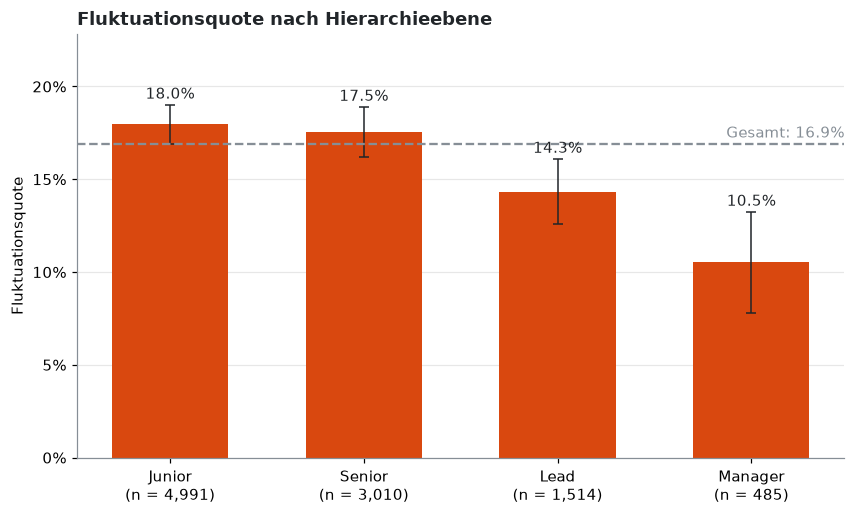

,anzahl,kuendigungen,quote,ki_unten,ki_oben
position,,,,,
Junior,4991,896,0.18,0.17,0.19
Senior,3010,528,0.18,0.16,0.19
Lead,1514,217,0.14,0.13,0.16
Manager,485,51,0.11,0.08,0.13


In [45]:
tab = fluktuation_nach_gruppe(df, "position")
plotting.rate_chart(tab, "Fluktuationsquote nach Hierarchieebene",
                    reference=gesamtquote, save_as="06_h1a_position")
plt.show()
tab

**Erkenntnis H1a:** Die Fluktuationsquote unterscheidet sich signifikant zwischen den
Hierarchieebenen (χ² = 25,97, df = 3, p < 0,001) und sinkt mit steigender Ebene:
Junior 18,0 %, Senior 17,5 %, Lead 14,3 %, Manager 10,5 %.
Hypothese teilweise bestätigt: Junior und Manager liegen wie erwartet am höchsten bzw.
niedrigsten; Junior und Senior unterscheiden sich jedoch nicht nennenswert
(überlappende Konfidenzintervalle). Die erwartete erhöhte Fluktuation bei Lead
(Engpass zur Manager-Ebene) zeigt sich nicht.
Junior und Senior stellen 80 % der Belegschaft und 84 % der Kündigungen.
Hinweis: Hierarchieebene, Alter und Betriebszugehörigkeit hängen zusammen;
der Einfluss der Ebene allein ist hier noch nicht isoliert. 

Mögliche Erklärung: Das deutlich höhere Gehaltsniveau auf Lead-Ebene könnte fehlende
Aufstiegsperspektiven ausgleichen (nicht überprüft).

abteilung: χ² = 124.80, df = 6, p < 0.001


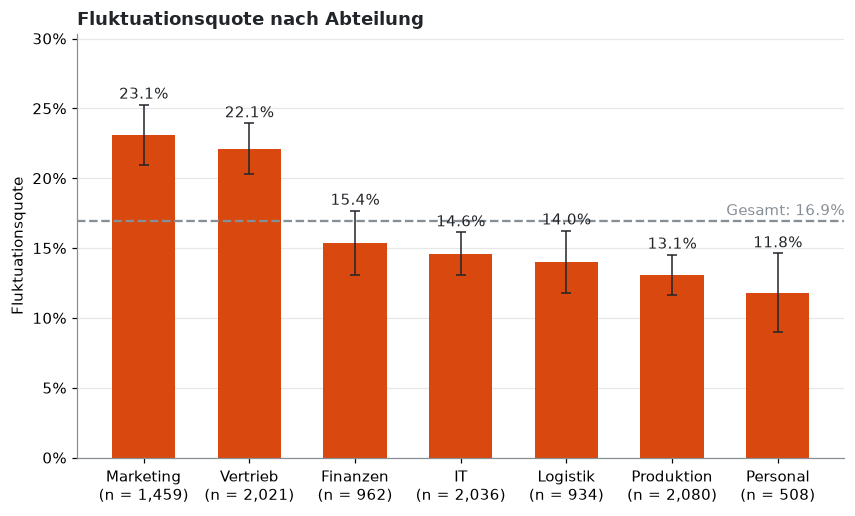

,anzahl,kuendigungen,quote,ki_unten,ki_oben
abteilung,,,,,
Marketing,1459,337,0.23,0.21,0.25
Vertrieb,2021,447,0.22,0.20,0.24
Finanzen,962,148,0.15,0.13,0.18
IT,2036,297,0.15,0.13,0.16
Logistik,934,131,0.14,0.12,0.16
Produktion,2080,272,0.13,0.12,0.15
Personal,508,60,0.12,0.09,0.15


In [46]:
tab = fluktuation_nach_gruppe(df, "abteilung")
tab = tab.sort_values("quote", ascending=False)
plotting.rate_chart(tab, "Fluktuationsquote nach Abteilung",
                    reference=gesamtquote, save_as="06_h1b_abteilung")
plt.show()
tab

**Erkenntnis H1b (explorativ):** Die Fluktuationsquote unterscheidet sich deutlich zwischen
den Abteilungen (χ² = 124,80, df = 6, p < 0,001). Es zeigen sich zwei Gruppen:
Marketing (23,1 %) und Vertrieb (22,1 %) liegen klar über dem Durchschnitt von 16,9 %;
die übrigen Abteilungen liegen zwischen 11,8 % (Personal) und 15,4 % (Finanzen), ohne
nennenswerte Unterschiede untereinander.
Marketing und Vertrieb stellen 35 % der Belegschaft, aber 46 % der Kündigungen.
Hinweis: Unterschiede in der Zusammensetzung der Abteilungen (z. B. Hierarchieebenen)
sind hier noch nicht berücksichtigt.

Mögliche Erklärung: Kompetenzen in Marketing und Vertrieb sind branchenübergreifend
einsetzbar, was die Wechselmöglichkeiten erhöht; im Vertrieb kommt häufig ein hoher
Zieldruck hinzu (nicht überprüft).

alter_gruppe: χ² = 2.99, df = 4, p = 0.560


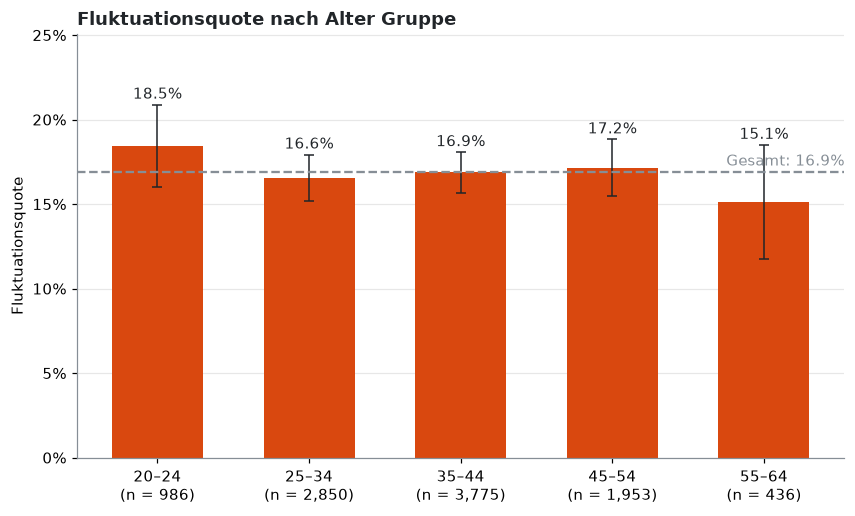

,anzahl,kuendigungen,quote,ki_unten,ki_oben
alter_gruppe,,,,,
20–24,986,182,0.18,0.16,0.21
25–34,2850,472,0.17,0.15,0.18
35–44,3775,637,0.17,0.16,0.18
45–54,1953,335,0.17,0.15,0.19
55–64,436,66,0.15,0.12,0.19


In [47]:
tab = fluktuation_nach_gruppe(df, "alter_gruppe")
plotting.rate_chart(tab, "Fluktuationsquote nach Alter Gruppe",
                    reference=gesamtquote, save_as="06_h1c_alter_gruppe")
plt.show()
tab

**Erkenntnis H1c:** Zwischen Altersgruppe und Fluktuation besteht kein signifikanter
Zusammenhang (χ² = 2,99, df = 4, p = 0,56). Die Quoten liegen zwischen 15,1 % (55–64)
und 18,5 % (20–24) und damit nahe am Durchschnitt von 16,9 %.
Hypothese nicht bestätigt: Die Fluktuation sinkt nicht mit dem Alter.
Konsequenz: Die höhere Fluktuation auf Junior-Ebene (H1a) ist nicht durch das Alter erklärbar.

zugehoerigkeit_gruppe: χ² = 119.46, df = 4, p < 0.001


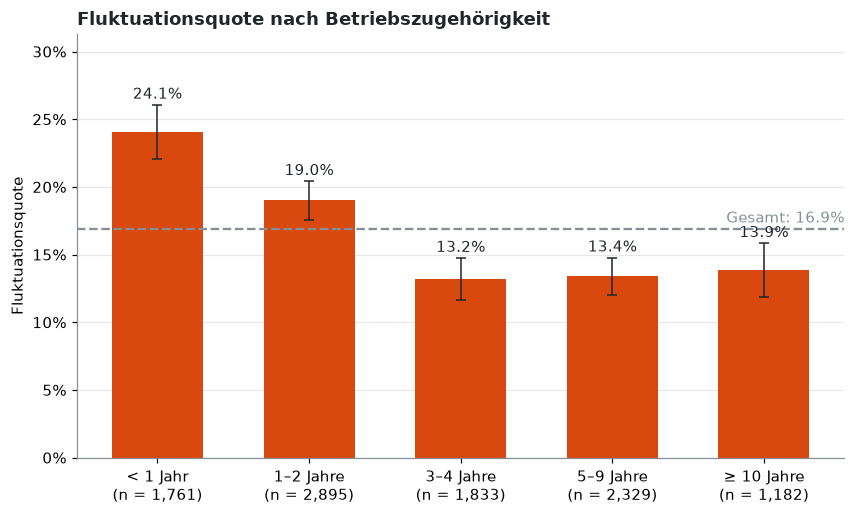

,anzahl,kuendigungen,quote,ki_unten,ki_oben
zugehoerigkeit_gruppe,,,,,
< 1 Jahr,1761,424,0.24,0.22,0.26
1–2 Jahre,2895,550,0.19,0.18,0.20
3–4 Jahre,1833,242,0.13,0.12,0.15
5–9 Jahre,2329,312,0.13,0.12,0.15
≥ 10 Jahre,1182,164,0.14,0.12,0.16


In [48]:
tab = fluktuation_nach_gruppe(df, "zugehoerigkeit_gruppe")
plotting.rate_chart(tab, "Fluktuationsquote nach Betriebszugehörigkeit",
                    reference=gesamtquote, save_as="06_h2betriebszugehoerigkeit")
plt.show()
tab

In [49]:
pd.pivot_table(
    df, values=config.TARGET, index="zugehoerigkeit_gruppe", columns="position",
    aggfunc="mean", observed=True,
).round(3)

position,Junior,Senior,Lead,Manager
zugehoerigkeit_gruppe,,,,
< 1 Jahr,0.25,0.24,0.24,0.15
1–2 Jahre,0.21,0.19,0.15,0.13
3–4 Jahre,0.14,0.14,0.09,0.12
5–9 Jahre,0.15,0.14,0.10,0.07
≥ 10 Jahre,0.15,0.15,0.13,0.04


In [50]:
# Group sizes behind each rate (reliability check)
pd.crosstab(df["zugehoerigkeit_gruppe"], df["position"])

position,Junior,Senior,Lead,Manager
zugehoerigkeit_gruppe,,,,
< 1 Jahr,861,530,283,87
1–2 Jahre,1398,915,440,142
3–4 Jahre,943,539,265,86
5–9 Jahre,1187,669,357,116
≥ 10 Jahre,602,357,169,54


**Erkenntnis (Betriebszugehörigkeit × Hierarchieebene):** Hierarchieebene und
Betriebszugehörigkeit sind in diesem Datensatz nahezu unabhängig: Der Junior-Anteil liegt
in jeder Gruppe nach Betriebszugehörigkeit bei 48–51 %. Beide Zusammenhänge mit der
Fluktuation sind daher eigenständig und nicht durch Konfundierung erklärbar.
Innerhalb jeder Ebene sinkt die Quote mit der Betriebszugehörigkeit (z. B. Junior:
25 % → 14–15 %); Lead und Manager liegen in den meisten Gruppen unter Junior und Senior.
Neue Leads (< 1 Jahr, n = 283) weisen mit 24 % eine ähnlich hohe Quote auf wie neue Juniors.
Juniors mit ≥ 10 Jahren (n = 602), ein möglicher Beförderungsstau, kündigen nicht häufiger
(15 %). Die Unabhängigkeit von Ebene und Betriebszugehörigkeit ist für ein reales
Unternehmen untypisch und vermutlich ein Merkmal des synthetischen Datensatzes.
Manager-Werte beruhen auf kleinen Gruppen (54–142 Personen) und sind nur eingeschränkt belastbar.

ueberstunden_gruppe: χ² = 15.24, df = 4, p = 0.004


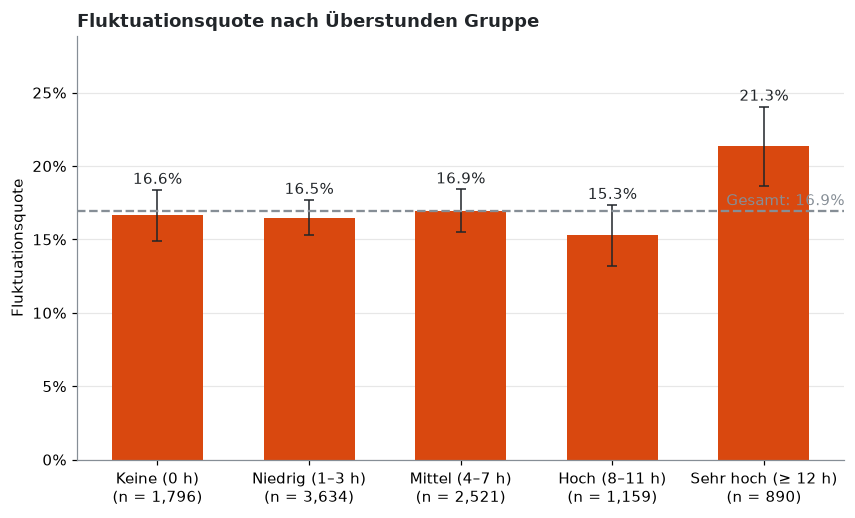

,anzahl,kuendigungen,quote,ki_unten,ki_oben
ueberstunden_gruppe,,,,,
Keine (0 h),1796,299,0.17,0.15,0.18
Niedrig (1–3 h),3634,599,0.16,0.15,0.18
Mittel (4–7 h),2521,427,0.17,0.15,0.18
Hoch (8–11 h),1159,177,0.15,0.13,0.17
Sehr hoch (≥ 12 h),890,190,0.21,0.19,0.24


In [51]:
tab = fluktuation_nach_gruppe(df, "ueberstunden_gruppe")
plotting.rate_chart(tab, "Fluktuationsquote nach Überstunden Gruppe",
                    reference=gesamtquote, save_as="06_h3a_ueberstunden_gruppe")
plt.show()
tab

**Erkenntnis H3a:** Zwischen Überstundengruppe und Fluktuation besteht ein signifikanter,
aber moderater Zusammenhang (χ² = 15,24, df = 4, p = 0,004). Die Quoten der Gruppen
bis 11 h liegen einheitlich bei 15–17 %; nur bei ≥ 12 h steigt sie deutlich auf 21,3 %
(Schwelleneffekt statt kontinuierlichem Anstieg).
Hypothese teilweise bestätigt: Die höchste Quote zeigt sich wie erwartet bei sehr hohen
Überstunden; ein schrittweiser Rückgang sowie ein erhöhter Wert ohne Überstunden zeigen sich nicht.
→ Maßnahmen gezielt bei Mitarbeitenden mit ≥ 12 Überstunden pro Monat (9 % der Belegschaft)
statt einer allgemeinen Reduktion.

gehaltsquartil: χ² = 1.10, df = 3, p = 0.778


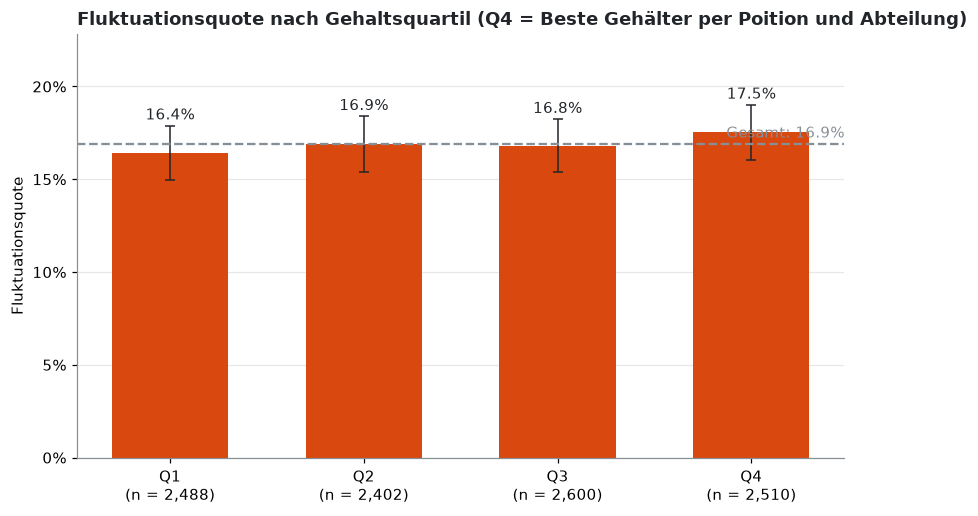

,anzahl,kuendigungen,quote,ki_unten,ki_oben
gehaltsquartil,,,,,
Q1,2488,409,0.16,0.15,0.18
Q2,2402,406,0.17,0.15,0.18
Q3,2600,437,0.17,0.15,0.18
Q4,2510,440,0.18,0.16,0.19


In [52]:
tab = fluktuation_nach_gruppe(df, "gehaltsquartil")
plotting.rate_chart(tab, "Fluktuationsquote nach Gehaltsquartil (Q4 = Beste Gehälter per Poition und Abteilung)",
                    reference=gesamtquote, save_as="06_h3b_gehaltsquartil")
plt.show()
tab

**Erkenntnis H3b:** Zwischen dem relativen Gehalt innerhalb der Vergleichsgruppe
(Abteilung × Hierarchieebene) und der Fluktuation besteht kein Zusammenhang
(χ² = 1,10, df = 3, p = 0,78). Die Quoten liegen zwischen 16,4 % (Q1) und 17,5 % (Q4).
Hypothese nicht bestätigt.
→ Gehaltsanpassungen innerhalb der Vergleichsgruppen lassen nach diesen Daten keinen
Rückgang der Fluktuation erwarten; wirksamere Ansatzpunkte sind die ersten zwei
Beschäftigungsjahre, Marketing und Vertrieb sowie sehr hohe Überstunden.

In [53]:
from scipy.stats import spearmanr

# Mechanism behind H3b: do higher-paid employees (within their peer group) work more overtime?
rho, p = spearmanr(df["gehalt_rang"], df["ueberstunden_monat"])
print(f"Spearman ρ = {rho:.3f}, p = {p:.4f}")

Spearman ρ = 0.003, p = 0.7307


**Erkenntnis H3c:** Zwischen relativem Gehalt und Überstunden besteht kein Zusammenhang
(Spearman ρ = 0,003, p = 0,73). Hypothese nicht bestätigt.

zufriedenheit: χ² = 841.44, df = 4, p < 0.001


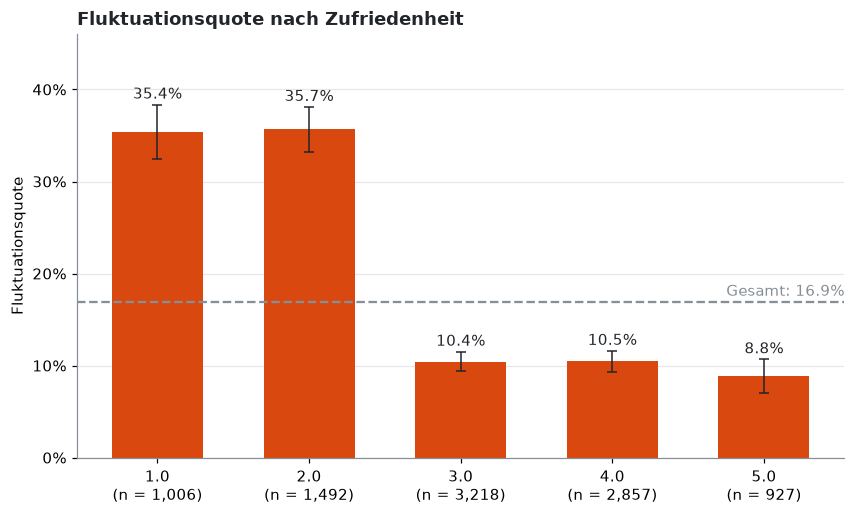

,anzahl,kuendigungen,quote,ki_unten,ki_oben
zufriedenheit,,,,,
1.00,1006,356,0.35,0.32,0.38
2.00,1492,532,0.36,0.33,0.38
3.00,3218,336,0.10,0.09,0.11
4.00,2857,299,0.10,0.09,0.12
5.00,927,82,0.09,0.07,0.11


In [54]:
tab = fluktuation_nach_gruppe(df, "zufriedenheit")
plotting.rate_chart(tab, "Fluktuationsquote nach Zufriedenheit",
                    reference=gesamtquote, save_as="06_explorativ_zufriedenheit")
plt.show()
tab

**Erkenntnis Zufriedenheit (explorativ):** Die Zufriedenheit zeigt den mit Abstand stärksten
Zusammenhang mit der Fluktuation (χ² = 841,44, df = 4, p < 0,001; n = 9.500).
Es besteht ein deutlicher Schwelleneffekt: Bei Zufriedenheit 1–2 liegt die Quote bei
35–36 %, bei 3–5 einheitlich bei 9–10 %. Unzufriedene Mitarbeitende kündigen damit mehr
als dreimal so häufig. Das Muster entspricht der vor der Auswertung formulierten Erwartung.
Die Bottom-2-Box (26 % der Befragten) umfasst 55 % der Kündigungen unter den Befragten.
Hinweis: Zufriedenheit ist vermutlich selbst Folge anderer Faktoren (z. B. Arbeitsbelastung,
Führung) und daher eher Frühindikator als Ursache.

In [55]:
df["abwesenheitstage_jahr"].quantile([0.25, 0.5, 0.75, 0.9])

0.25    6.00
0.50    8.00
0.75   10.00
0.90   12.00
Name: abwesenheitstage_jahr, dtype: float64

In [56]:
# Absence groups: boundaries follow percentiles (P25 = 6, P50 = 8, P75 = 10, P90 = 12)
abwesenheit_bins = [-1, 6, 8, 10, 12, np.inf]
abwesenheit_labels = ["0–6 Tage", "7–8 Tage", "9–10 Tage", "11–12 Tage", "≥ 13 Tage"]

df["abwesenheit_gruppe"] = pd.cut(
    df["abwesenheitstage_jahr"],
    bins=abwesenheit_bins,
    labels=abwesenheit_labels,
)

# Size of each group (count and share)
pd.DataFrame({
    "anzahl": df["abwesenheit_gruppe"].value_counts(sort=False),
    "anteil": df["abwesenheit_gruppe"].value_counts(sort=False, normalize=True).round(3),
})

,anzahl,anteil
abwesenheit_gruppe,,
0–6 Tage,3083,0.31
7–8 Tage,2841,0.28
9–10 Tage,2203,0.22
11–12 Tage,1232,0.12
≥ 13 Tage,641,0.06


abwesenheit_gruppe: χ² = 1.98, df = 4, p = 0.740


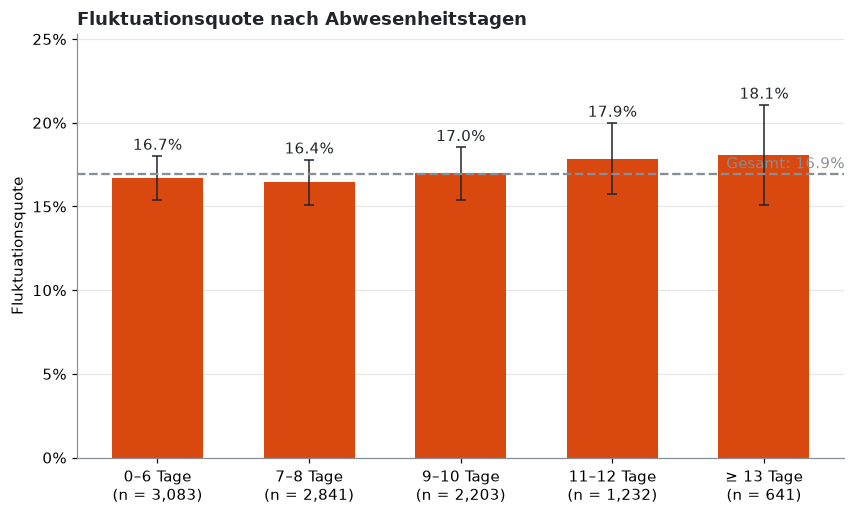

,anzahl,kuendigungen,quote,ki_unten,ki_oben
abwesenheit_gruppe,,,,,
0–6 Tage,3083,515,0.17,0.15,0.18
7–8 Tage,2841,467,0.16,0.15,0.18
9–10 Tage,2203,374,0.17,0.15,0.19
11–12 Tage,1232,220,0.18,0.16,0.20
≥ 13 Tage,641,116,0.18,0.15,0.21


In [57]:
tab = fluktuation_nach_gruppe(df, "abwesenheit_gruppe")
plotting.rate_chart(tab, "Fluktuationsquote nach Abwesenheitstagen",
                    reference=gesamtquote, save_as="06_explorativ_abwesenheit")
plt.show()
tab

**Erkenntnis Abwesenheit (explorativ):** Zwischen Abwesenheitstagen und Fluktuation besteht
kein Zusammenhang (χ² = 1,98, df = 4, p = 0,74). Die Quoten liegen zwischen 16,4 % und 18,1 %.
Das Muster entspricht der vor der Auswertung formulierten Erwartung.
→ Für das Modell ist kaum Informationsgewinn zu erwarten; die Sensitivitätsanalyse
(Modell mit und ohne Abwesenheitstage) wird zeigen, ob das Merkmal aus ethischen Gründen
entfernt werden kann.

## 7. Korrelationen

In [58]:
df

,mitarbeiter_id,alter,geschlecht,abteilung,position,eintrittsdatum,betriebszugehoerigkeit_jahre,betriebszugehoerigkeit_monate,gehalt_brutto,gehalt_final,gehalt_status,ueberstunden_monat,zufriedenheit,abwesenheitstage_jahr,gekuendigt,zufriedenheit_fehlt,ueberstunden_gruppe,alter_gruppe,zugehoerigkeit_gruppe,gehalt_rang,gehaltsquartil,abwesenheit_gruppe
0,MA-00000,42,weiblich,Produktion,Junior,2024-03-03,1,22,"48,071.00","48,071.00",Original,3,5.00,3,0,False,Niedrig (1–3 h),35–44,1–2 Jahre,0.81,Q4,0–6 Tage
1,MA-00001,36,weiblich,IT,Senior,2025-05-07,0,8,"53,178.00","53,178.00",Original,0,4.00,8,0,False,Keine (0 h),35–44,< 1 Jahr,0.21,Q1,7–8 Tage
2,MA-00002,44,männlich,Produktion,Junior,2025-12-20,0,0,"34,614.00","34,614.00",Original,10,2.00,5,0,False,Hoch (8–11 h),35–44,< 1 Jahr,0.14,Q1,0–6 Tage
3,MA-00003,53,weiblich,IT,Senior,2025-10-12,0,3,"59,594.00","59,594.00",Original,0,5.00,8,0,False,Keine (0 h),45–54,< 1 Jahr,0.39,Q2,7–8 Tage
4,MA-00004,35,männlich,Vertrieb,Senior,2021-04-13,4,57,"70,287.00","70,287.00",Original,0,4.00,8,0,False,Keine (0 h),35–44,3–4 Jahre,0.79,Q4,7–8 Tage
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,MA-09995,51,männlich,Finanzen,Junior,2020-05-18,5,67,"44,375.00","44,375.00",Original,21,2.00,9,1,False,Sehr hoch (≥ 12 h),45–54,5–9 Jahre,0.61,Q3,9–10 Tage
9996,MA-09996,20,weiblich,Personal,Junior,2023-08-04,2,29,"37,383.00","37,383.00",Original,1,5.00,8,0,False,Niedrig (1–3 h),20–24,1–2 Jahre,0.31,Q2,7–8 Tage
9997,MA-09997,30,männlich,Vertrieb,Lead,2024-09-01,1,16,"87,554.00","87,554.00",Original,1,1.00,9,0,False,Niedrig (1–3 h),25–34,1–2 Jahre,0.67,Q3,9–10 Tage
9998,MA-09998,42,männlich,Logistik,Junior,2018-08-23,7,88,"38,683.00","38,683.00",Original,5,3.00,11,0,False,Mittel (4–7 h),35–44,5–9 Jahre,0.30,Q2,11–12 Tage


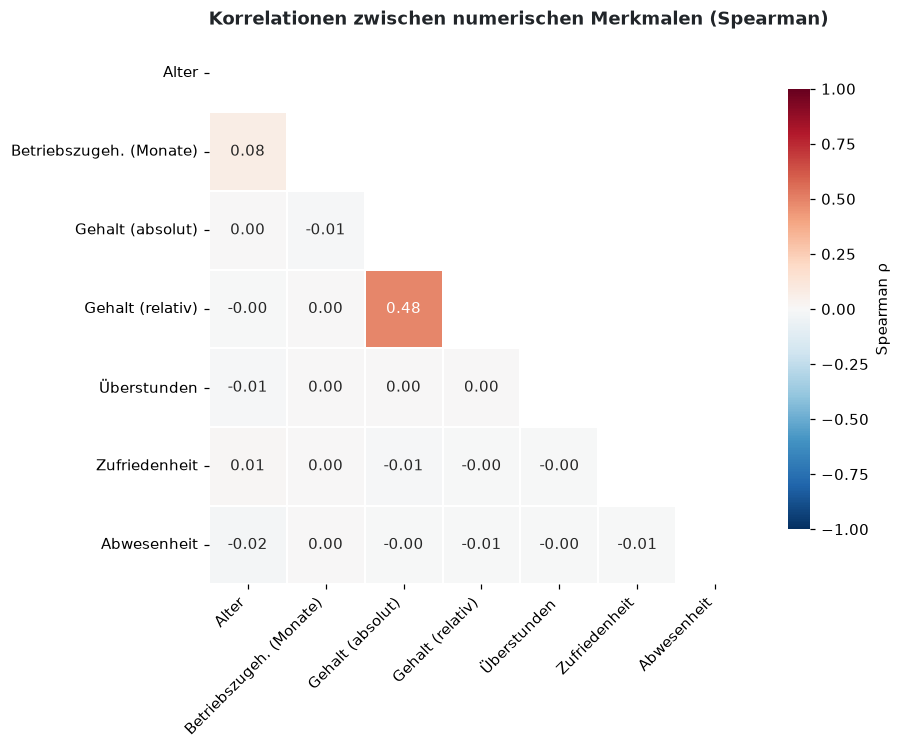

In [59]:
# Spearman correlation between numeric features (detect redundant variables before modelling)
numeric_cols = {
    "alter": "Alter",
    "betriebszugehoerigkeit_monate": "Betriebszugeh. (Monate)",
    "gehalt_final": "Gehalt (absolut)",
    "gehalt_rang": "Gehalt (relativ)",
    "ueberstunden_monat": "Überstunden",
    "zufriedenheit": "Zufriedenheit",
    "abwesenheitstage_jahr": "Abwesenheit",
}

corr = df[list(numeric_cols)].corr(method="spearman").rename(index=numeric_cols, columns=numeric_cols)

# Show only the lower triangle: the matrix is symmetric, the upper half repeats the values
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,   # diverging: blue = negative, red = positive, white = 0
    linewidths=1, linecolor="white",
    cbar_kws={"label": "Spearman ρ", "shrink": 0.8}, ax=ax,
)
ax.set_title("Korrelationen zwischen numerischen Merkmalen (Spearman)")
plt.xticks(rotation=45, ha="right")

plotting.save(fig, "07_korrelationsmatrix")
plt.show()

**Erkenntnis Korrelationen:** Zwischen den numerischen Merkmalen bestehen kaum Zusammenhänge
(|ρ| < 0,1), mit einer Ausnahme: absolutes und relatives Gehalt (ρ = 0,48), da das relative
Gehalt aus dem absoluten abgeleitet ist. Alter und Betriebszugehörigkeit hängen entgegen der
Erwartung kaum zusammen (ρ = 0,08).
→ Für das Modell besteht keine Multikollinearität zwischen den numerischen Merkmalen.
→ Die weitgehende Unabhängigkeit der Merkmale ist für ein reales Unternehmen untypisch und
spricht dafür, dass sie bei der Datengenerierung unabhängig erzeugt wurden
(siehe Limitation 5, synthetische Daten).

In [60]:
# Is satisfaction lower in high-attrition groups? (bridge or independent factor?)
for col in ["abteilung", "zugehoerigkeit_gruppe"]:
    display(
        df.groupby(col, observed=True)["zufriedenheit"]
          .agg(median="median", mittelwert="mean", anteil_unzufrieden=lambda s: (s <= 2).mean())
          .round(2)
    )

,median,mittelwert,anteil_unzufrieden
abteilung,,,
Finanzen,3.00,3.23,0.21
IT,3.00,3.13,0.25
Logistik,3.00,3.12,0.24
Marketing,3.00,3.10,0.26
Personal,3.00,3.22,0.20
Produktion,3.00,3.10,0.26
Vertrieb,3.00,3.10,0.26


,median,mittelwert,anteil_unzufrieden
zugehoerigkeit_gruppe,,,
< 1 Jahr,3.00,3.10,0.26
1–2 Jahre,3.00,3.14,0.25
3–4 Jahre,3.00,3.16,0.24
5–9 Jahre,3.00,3.11,0.25
≥ 10 Jahre,3.00,3.13,0.25


**Erkenntnis Zufriedenheit als Bindeglied:** Der Anteil unzufriedener Mitarbeitender
(Zufriedenheit 1–2) liegt in keiner Abteilung und keiner Gruppe nach Betriebszugehörigkeit
deutlich über dem Gesamtwert von 27 %. Erwartung nicht bestätigt: Zufriedenheit vermittelt
die höhere Fluktuation in Marketing, Vertrieb und den ersten Beschäftigungsjahren nicht;
die Faktoren wirken unabhängig voneinander.
→ Eine Steigerung der Zufriedenheit allein würde die Fluktuation in diesen Gruppen nicht senken;
erforderlich sind gruppenspezifische Maßnahmen.
→ Für das Modell liefern Zufriedenheit, Abteilung und Betriebszugehörigkeit jeweils eigenständige Information.

**Methodischer Hinweis:** Die Spearman-Korrelation erfasst nur monotone Zusammenhänge
(stetig steigend oder fallend). Nicht-monotone Muster, z. B. U-förmige Verläufe, würden
einen Wert nahe 0 ergeben. Daher wurden die relevanten Zusammenhänge zusätzlich über
Gruppenvergleiche geprüft (z. B. Anteil unzufriedener Mitarbeitender je Gruppe nach
Betriebszugehörigkeit). Beide Verfahren kommen übereinstimmend zu dem Ergebnis, dass kein
Zusammenhang besteht. Auf Streudiagramme wurde verzichtet, da sich bei 10.000 Personen und
ganzzahligen Werten (z. B. Zufriedenheit 1–5) die Punkte stark überlagern und
Gruppenvergleiche aussagekräftiger sind.

## 8. Erkenntnisse

- Fluktuationsquote gesamt: 16,9 % (bestätigt die HR-Schätzung von ca. 17 %)
- Fehlende Zufriedenheitswerte hängen nicht mit Kündigungen zusammen

**Hypothesen**
- H1a teilweise bestätigt: Fluktuation sinkt mit der Hierarchieebene (Junior 18,0 % → Manager 10,5 %); kein erhöhtes Risiko bei Lead.
- H1b (explorativ): Marketing (23,1 %) und Vertrieb (22,1 %) liegen deutlich über dem Durchschnitt; übrige Abteilungen 11,8–15,4 %.
- H1c nicht bestätigt: Kein Zusammenhang zwischen Alter und Fluktuation (15,1–18,5 %, p = 0,56).
- H2 teilweise bestätigt: Höchste Quote im ersten Jahr (24,1 %), Stabilisierung bereits ab 3 Jahren bei 13–14 % statt ab 5 Jahren bei ca. 10 %.
- H3a teilweise bestätigt: Nur bei ≥ 12 Überstunden pro Monat erhöhte Quote (21,3 %); darunter einheitlich 15–17 % (Schwelleneffekt).
- H3b nicht bestätigt: Kein Zusammenhang zwischen relativem Gehalt und Fluktuation (16,4–17,5 %, p = 0,78).
- H3c nicht bestätigt: Relatives Gehalt und Überstunden hängen nicht zusammen (ρ = 0,003).

**Explorative Analysen**
- Zufriedenheit: stärkster Zusammenhang (χ² = 841); bei Zufriedenheit 1–2 kündigen 35–36 %, bei 3–5 nur 9–10 %.
- Abwesenheit: kein Zusammenhang mit der Fluktuation (16,4–18,1 %, p = 0,74).
- Korrelationen: keine Multikollinearität zwischen numerischen Merkmalen; Merkmale weitgehend unabhängig (vermutlich synthetisch erzeugt).
- Zufriedenheit, Abteilung und Betriebszugehörigkeit wirken unabhängig voneinander auf die Fluktuation.

**Zusammenfassung für die Personalabteilung**

Die Fluktuation bei Sonnenfeld (16,9 %) hängt vor allem mit drei voneinander unabhängigen
Faktoren zusammen:

1. **Zufriedenheit:** Unzufriedene Mitarbeitende (1–2) kündigen mehr als dreimal so häufig
   (35 % vs. 9–10 %).
2. **Betriebszugehörigkeit:** In den ersten zwei Jahren liegt die Quote bei 19–24 %;
   diese Gruppe verursacht 58 % aller Kündigungen.
3. **Abteilung:** Marketing und Vertrieb (22–23 %) verursachen 46 % aller Kündigungen.

Sehr hohe Überstunden (≥ 12 h/Monat) erhöhen das Risiko moderat (21 %).
Alter, relatives Gehalt und Abwesenheit zeigen keinen Zusammenhang.

Da die Faktoren unabhängig wirken, sind gruppenspezifische Maßnahmen nötig:
Onboarding und Bindung in den ersten zwei Jahren, eine gezielte Analyse der Ursachen in
Marketing und Vertrieb sowie regelmäßige Erfassung der Zufriedenheit als Frühindikator.

In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   mitarbeiter_id                 10000 non-null  str     
 1   alter                          10000 non-null  int64   
 2   geschlecht                     10000 non-null  str     
 3   abteilung                      10000 non-null  str     
 4   position                       10000 non-null  category
 5   eintrittsdatum                 10000 non-null  str     
 6   betriebszugehoerigkeit_jahre   10000 non-null  int64   
 7   betriebszugehoerigkeit_monate  10000 non-null  int64   
 8   gehalt_brutto                  9800 non-null   float64 
 9   gehalt_final                   10000 non-null  float64 
 10  gehalt_status                  10000 non-null  str     
 11  ueberstunden_monat             10000 non-null  int64   
 12  zufriedenheit                  9500 non-null